# 2 km flow direction grid for the UK

Derives a 2 km D8 flow direction raster for the British Isles in British National Grid (EPSG:27700)
from the HydroSHEDS v1 hydrologically conditioned 3" DEM (`eu_con_3s`). The grid is fully resolved:
every land cell has a strictly downhill path to the sea, so there are no pits, flats, depressions or loops.

The method:

1. **Grid.** A 2 km grid aligned to the BNG origin, covering GB, the island of Ireland and the Isle of Man.
   The whole of Ireland is included so that cross-border catchments in Northern Ireland (e.g. Erne, Foyle)
   are routed correctly.
2. **Aggregation.** Each 2 km cell takes the *minimum* elevation of the 90 m land pixels inside it, and a
   cell is land if at least half of its area is land. Rivers are burned into the HydroSHEDS conditioned
   DEM, so the minimum keeps valley floors, including gorges narrower than a cell (e.g. the Severn at
   Ironbridge). Averaging fills those gorges in and diverts whole catchments. HydroSHEDS stops at 60°N,
   so cells north of that (northern Shetland) are taken from EuroDEM 2023 instead.
3. **Land/sea mask.** Mainland Europe (anything touching the grid edge) is removed. Enclosed
   inland water, if any, is treated as land so it is routed through.
4. **River enforcement (GB only).** On flat lowland a 2 km DEM can't tell which of two neighbouring valleys
   a river takes. Rivers in OS Open Rivers with at least 10 km of channel upstream are rasterised, and their
   cells are given D8 directions that follow the mapped river. Those cells are also lowered by 50 m, so
   neighbouring cells drain into them. Northern Ireland and the Republic of Ireland are DEM-only.
5. **Conditioning.** Priority-Flood+ε ([Barnes et al., 2014](https://doi.org/10.1016/j.cageo.2013.04.024)),
   seeded from coastal cells, fills depressions and gives flats a tiny gradient towards their outlet. It
   is adapted so that a river cell is always reached from its mapped downstream cell, which makes the
   enforced directions downhill too.
6. **Flow direction.** D8 steepest descent on the conditioned DEM, plus the enforced directions on river
   cells. It uses the same ESRI encoding as the HMF 5 km grid (`1` E, `2` SE, `4` S, `8` SW, `16` W,
   `32` NW, `64` N, `128` NE). Coastal cells drain straight to the sea.
7. **Validation.** Every land cell is traced to the sea, flow accumulation is checked against pysheds, and
   upstream areas at all NRFA gauges (≥50 km²) are compared with their published catchment areas, with
   and without river enforcement.

In [1]:
import os
import tomllib
import urllib.request
from pathlib import Path
import heapq
import numpy as np
import numba
import rasterio
from rasterio.transform import from_origin
from rasterio.warp import reproject, transform_bounds, Resampling
from rasterio.windows import from_bounds, Window
import rasterio.features
from pyproj import Transformer
from scipy import ndimage
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

# Data locations are set in paths.toml in the project root (copy paths.example.toml to make it), or in the
# file named by the PFASE_PATHS environment variable. Relative paths in it are relative to that file
path_config = Path(os.environ.get('PFASE_PATHS', '../paths.toml')).expanduser().resolve()
if not path_config.exists():
    raise FileNotFoundError(f'{path_config} not found. Copy paths.example.toml to paths.toml and set the paths in it')
config = tomllib.loads(path_config.read_text())


def config_path(key):
    return (path_config.parent / Path(config[key]).expanduser()).resolve()

path_hydrosheds = config_path('hydrosheds_dem')
path_eurodem = config_path('eurodem')
path_rivers = config_path('os_rivers')
path_nrfa = config_path('nrfa_stations')
path_out = config_path('data_dir')
missing = [p for p in (path_hydrosheds, path_eurodem, path_rivers) if not p.exists()]
if missing:
    raise FileNotFoundError(f'Inputs not found (paths.example.toml lists their sources): {", ".join(map(str, missing))}')
path_out.mkdir(parents=True, exist_ok=True)
if not path_nrfa.exists():  # NRFA gauging station list, downloaded on first run
    path_nrfa.parent.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve('https://nrfaapps.ceh.ac.uk/nrfa/ws/station-info?station=*&format=csv'
                               '&fields=id,name,catchment-area,easting,northing,grid-reference', path_nrfa)

BNG = 'EPSG:27700'
RES = 2000
NODATA = -9999
MIN_UP_KM = 10  # Enforce rivers with at least this much channel length upstream
BURN = 50       # and lower their cells by this much (m)
# Grid extent (BNG metres), aligned to the BNG origin (so also aligned with the HMF 5 km grid at 10 km
# multiples). x < 0 is needed to cover the west of Ireland
X0, X1, Y0, Y1 = -250_000, 700_000, 0, 1_250_000
ncol, nrow = (X1 - X0) // RES, (Y1 - Y0) // RES
transform = from_origin(X0, Y1, RES, RES)
print(f'Grid: {ncol} cols x {nrow} rows')

Grid: 475 cols x 625 rows


## Aggregate the DEMs onto the 2 km grid

`aggregate` reads the source DEM pixels under a BNG bounding box and aggregates them onto the 2 km grid.
It returns the minimum elevation of the land pixels in each cell and the fraction of the cell that is land
(sea is nodata in both DEMs). Cells outside the source's coverage are NaN.

Minimum rather than mean elevation matters a lot here. With mean aggregation the conditioned grid is just as
"resolved", but in a first attempt the upper Severn was routed north through the Shropshire plain because
the Ironbridge Gorge disappeared. That put the Severn at Bewdley at −78% of its catchment area and gave a
mean absolute error of 19% over the gauges below, compared with about 4% using the minimum.

In [2]:
def aggregate(path, bounds):
    with rasterio.open(path) as src:
        win = from_bounds(*transform_bounds(BNG, src.crs, *bounds, densify_pts=101), transform=src.transform)
        win = win.intersection(Window(0, 0, src.width, src.height))
        c0, r0 = int(np.floor(win.col_off)), int(np.floor(win.row_off))
        win = Window(c0, r0, int(np.ceil(win.col_off + win.width)) - c0, int(np.ceil(win.row_off + win.height)) - r0)
        dem = src.read(1, window=win)
        src_transform, src_crs, src_nodata = src.window_transform(win), src.crs, src.nodata
    elev = np.full((nrow, ncol), np.nan, dtype=np.float32)
    frac = np.full((nrow, ncol), np.nan, dtype=np.float32)
    kw = dict(src_transform=src_transform, src_crs=src_crs, dst_transform=transform, dst_crs=BNG, dst_nodata=np.nan)
    reproject(dem.astype(np.float32), elev, src_nodata=src_nodata, resampling=Resampling.min, **kw)
    # The land mask has no nodata of its own (-1 never occurs), so sea pixels count towards the average
    reproject((dem != src_nodata).astype(np.float32), frac, src_nodata=-1, resampling=Resampling.average, **kw)
    return elev, frac

elev_hs, frac_hs = aggregate(path_hydrosheds, (X0, Y0, X1, Y1))
# EuroDEM is only needed in the north, where HydroSHEDS (which stops at 60°N) runs out
elev_eu, frac_eu = aggregate(path_eurodem, (X0, 1_000_000, X1, Y1))

HydroSHEDS is used wherever a cell lies entirely south of 60°N, and EuroDEM everywhere else. As a check
on the join, the two sources are compared over the land cells in the 59–60°N band where both exist.

In [3]:
# Latitude of every cell corner, to find cells that HydroSHEDS fully covers
xe, ye = np.meshgrid(X0 + RES * np.arange(ncol + 1), Y1 - RES * np.arange(nrow + 1))
_, lat = Transformer.from_crs(BNG, 'EPSG:4326', always_xy=True).transform(xe, ye)
lat_max = np.maximum.reduce([lat[:-1, :-1], lat[:-1, 1:], lat[1:, :-1], lat[1:, 1:]])
use_eu = lat_max > 60
elev = np.where(use_eu, elev_eu, elev_hs)
frac = np.where(use_eu, frac_eu, frac_hs)

lat_min = np.minimum.reduce([lat[:-1, :-1], lat[:-1, 1:], lat[1:, :-1], lat[1:, 1:]])
band = (lat_min > 59) & ~use_eu & (frac_hs >= 0.5) & (frac_eu >= 0.5)
diff = elev_eu[band] - elev_hs[band]
print(f'59-60°N overlap ({band.sum()} cells): EuroDEM - HydroSHEDS mean {diff.mean():.1f} m, '
      f'RMSE {np.sqrt((diff**2).mean()):.1f} m')
print(f'Land cells (>= 50% land) taken from EuroDEM: {(use_eu & (frac >= 0.5)).sum()}')

59-60°N overlap (156 cells): EuroDEM - HydroSHEDS mean 2.0 m, RMSE 6.1 m
Land cells (>= 50% land) taken from EuroDEM: 360


## Land/sea mask

Land is any cell that is at least 50% land. Land masses that touch the grid edge (mainland Europe, around
Calais) are removed, and so is any land that doesn't touch the edge but is too far from the British
Isles to be part of them (there shouldn't be any). Non-land cells that aren't connected to the open sea
would be sinks, so they are turned into land, taking the elevation of the nearest land cell if they
have none of their own.

In [4]:
eight = np.ones((3, 3), dtype=bool)
land = np.nan_to_num(frac) >= 0.5

labels, n = ndimage.label(land, structure=eight)
edge_labels = np.unique(np.concatenate([labels[0], labels[-1], labels[:, 0], labels[:, -1]]))
edge_labels = edge_labels[edge_labels > 0]
for l in edge_labels:
    print(f'Removing land mass touching grid edge: {(labels == l).sum()} cells')
land &= ~np.isin(labels, edge_labels)

water_labels, _ = ndimage.label(~land, structure=eight)
sea_labels = np.unique(np.concatenate([water_labels[0], water_labels[-1], water_labels[:, 0], water_labels[:, -1]]))
enclosed = ~land & ~np.isin(water_labels, sea_labels)
print(f'Enclosed non-land cells converted to land: {enclosed.sum()} '
      f'in {len(np.unique(water_labels[enclosed]))} water bodies')
land |= enclosed
nearest = ndimage.distance_transform_edt(np.isnan(elev) | ~land, return_distances=False, return_indices=True)
elev = np.where(land & np.isnan(elev), elev[tuple(nearest)], elev)

assert not land[[0, -1]].any() and not land[:, [0, -1]].any(), 'Land on the grid edge'
assert not np.isnan(elev[land]).any()
n_land = land.sum()
print(f'{n_land} land cells ({n_land * RES**2 / 1e6:,.0f} km2) in {ndimage.label(land, structure=eight)[1]} land masses')

Removing land mass touching grid edge: 1680 cells
Enclosed non-land cells converted to land: 111 in 33 water bodies
79512 land cells (318,048 km2) in 69 land masses


## Enforce the OS Open Rivers network

OS Open Rivers `WatercourseLink`s are digitised in flow direction (all are `flow = in direction`). Canals
are dropped because they cross catchment divides. Each link's **upstream channel length** is its own
length plus that of every link upstream of it, worked out with a topological sort of the node graph.
This stands in for catchment size: there is roughly 0.65 km of channel per km² in GB, so 10 km is about
15 km². Links in the few loops in the network can't be ordered and are left out.

`MIN_UP_KM` and `BURN` were chosen by comparing upstream areas with all NRFA gauges of at least 50 km²
(see the validation below). Median absolute error was 11% without enforcement, 4.5% with 10 km / 50 m,
6% with 20 km and 8% with 50 km. A 5 km threshold has a slightly lower median (3.9%), but the denser
network has dead ends (e.g. where the Wyre meets the Lancaster Canal at Garstang), and releasing those
diverts the upper Wyre to Pilling again.

`link_cells` turns each link into its ordered sequence of 2 km cells. Where the line wanders out of a cell
and back, the loop is cut out. Each cell then points at the next cell along the link. Links are processed
from the largest upstream length down, so where rivers share a cell the bigger one sets its direction. Any
loops left in the enforced directions (rare, where rivers cross back and forth between two cells) are
broken by dropping the enforcement on the cell belonging to the smallest river.

In [5]:
links = gpd.read_file(path_rivers, columns=['startNode', 'endNode', 'form', 'flow', 'length'])
assert (links.flow == 'in direction').all()
links = links[links.form != 'canal'].reset_index(drop=True)
nodes = pd.Index(pd.concat([links.startNode, links.endNode]).unique())


@numba.njit
def upstream_length(start, end, length, n_nodes):
    # Upstream channel length (including itself) of each link, or -1 if it is in a loop
    order = np.argsort(start)
    first = np.searchsorted(start[order], np.arange(n_nodes + 1))
    remaining = np.zeros(n_nodes, dtype=np.int64)
    for e in end:
        remaining[e] += 1
    arriving = np.zeros(n_nodes)
    up = np.full(len(start), -1.0)
    queue = [n for n in range(n_nodes) if remaining[n] == 0]
    while len(queue) > 0:
        n = queue.pop()
        for idx in range(first[n], first[n + 1]):
            i = order[idx]
            up[i] = arriving[n] + length[i]
            arriving[end[i]] += up[i]
            remaining[end[i]] -= 1
            if remaining[end[i]] == 0:
                queue.append(end[i])
    return up


links['up_km'] = upstream_length(nodes.get_indexer(links.startNode), nodes.get_indexer(links.endNode),
                                 links['length'].to_numpy(float), len(nodes)) / 1e3
rivers = links[links.up_km >= MIN_UP_KM].sort_values('up_km', ascending=False)
print(f'{len(links)} non-canal links ({(links.up_km < 0).sum()} in loops); {len(rivers)} with >= {MIN_UP_KM} km upstream, '
      f'{rivers.length.sum() / 1e3:,.0f} km of channel')


def link_cells(geom, step=100.0):
    seq = []
    for d in np.append(np.arange(0, geom.length, step), geom.length):
        pt = geom.interpolate(d)
        rc = (int((Y1 - pt.y) // RES), int((pt.x - X0) // RES))
        if rc in seq:
            del seq[seq.index(rc) + 1:]
        else:
            seq.append(rc)
    return seq


# target: flat index of each river cell's enforced downstream cell (-1 = not enforced)
target = np.full((nrow, ncol), -1, dtype=np.int64)
target_up_km = np.zeros((nrow, ncol))
for geom, up_km in zip(rivers.geometry, rivers.up_km):
    seq = link_cells(geom)
    for (r, c), (rr, cc) in zip(seq[:-1], seq[1:]):
        if land[r, c] and target[r, c] < 0:
            target[r, c] = rr * ncol + cc
            target_up_km[r, c] = up_km

# Break loops in the enforced directions
tflat = target.ravel()
state = np.zeros(tflat.size, dtype=np.int8)  # 0 unseen, 1 on the current path, 2 done
n_broken = 0
for start in np.flatnonzero(tflat >= 0):
    path, n = [], start
    while n >= 0 and state[n] == 0:
        state[n] = 1
        path.append(n)
        n = tflat[n]
    if n >= 0 and state[n] == 1:
        loop = path[path.index(n):]
        tflat[min(loop, key=lambda k: target_up_km.flat[k])] = -1
        n_broken += 1
    state[path] = 2
print(f'{(target >= 0).sum()} river cells enforced ({100 * (target >= 0).sum() / land.sum():.0f}% of land); '
      f'{n_broken} loops broken')

199340 non-canal links (287 in loops); 40222 with >= 10 km upstream, 46,347 km of channel


21384 river cells enforced (27% of land); 20 loops broken


## Condition the DEM and derive flow directions

`priority_flood_eps` floods the DEM inwards from the coast, always processing the lowest unvisited
cell next. Each cell is visited from an already-visited neighbour, and if it isn't higher than that
neighbour it is raised to the next representable float above it. So every inland cell ends up strictly
higher than a neighbour that is closer (along the flood) to the sea. Depressions are therefore filled, and
flats get a gradient towards their outlet. Elevations are kept as float64 so the ε increments survive.

River cells are only visited from their enforced downstream cell, so they end up strictly higher than it
and the enforced direction is downhill. If the flood stalls because an enforced chain has no way out (a
dead end in the network, completely surrounded by other enforced cells), enforcement is released on the
unvisited cells next to visited ones, which are then treated as visited from their lowest visited
neighbour. This repeats until everything is reached. With the current settings nothing is released.

`d8` then points each cell at its steepest downhill neighbour (slope weighted by distance), and
`apply_targets` overwrites river cells with their enforced direction. Coastal cells point at an adjacent
sea cell, preferring cardinal neighbours, unless they are river cells enforced to flow along the coast.

In [6]:
# D8 neighbour offsets (row down, col right) and ESRI codes: E, SE, S, SW, W, NW, N, NE
DI = np.array([0, 1, 1, 1, 0, -1, -1, -1])
DJ = np.array([1, 1, 0, -1, -1, -1, 0, 1])
CODES = np.array([1, 2, 4, 8, 16, 32, 64, 128])
DIST = RES * np.array([1, np.sqrt(2)] * 4)
CARDINAL_FIRST = np.array([0, 2, 4, 6, 1, 3, 5, 7])


@numba.njit
def priority_flood_eps(z, land, target):
    nrow, ncol = z.shape
    z = z.copy()
    target = target.copy()
    closed = ~land
    heap = [(0.0, np.int64(0))]
    heap.pop()
    pit = np.empty(land.sum(), dtype=np.int64)
    head, tail = 0, 0
    # Seed with coastal cells, except river cells enforced to flow inland (land is never on the grid
    # edge, so neighbours are always in bounds)
    for i in range(nrow):
        for j in range(ncol):
            t = target[i, j]
            if land[i, j] and not (t >= 0 and land[t // ncol, t % ncol]):
                for k in range(8):
                    if not land[i + DI[k], j + DJ[k]]:
                        heapq.heappush(heap, (z[i, j], np.int64(i * ncol + j)))
                        closed[i, j] = True
                        break
    n_released = 0
    while True:
        while len(heap) > 0 or head < tail:
            if head < tail:
                c = pit[head]
                head += 1
            else:
                c = heapq.heappop(heap)[1]
            i, j = c // ncol, c % ncol
            z_up = np.nextafter(z[i, j], np.inf)
            for k in range(8):
                ii, jj = i + DI[k], j + DJ[k]
                if closed[ii, jj] or (target[ii, jj] >= 0 and target[ii, jj] != c):
                    continue
                closed[ii, jj] = True
                if z[ii, jj] <= z_up:
                    z[ii, jj] = z_up
                    pit[tail] = ii * ncol + jj
                    tail += 1
                else:
                    heapq.heappush(heap, (z[ii, jj], np.int64(ii * ncol + jj)))
        # Release unvisited cells bordering visited ones, if the flood has stalled
        released = []
        for i in range(nrow):
            for j in range(ncol):
                if not closed[i, j]:
                    z_low = np.inf
                    for k in range(8):
                        if closed[i + DI[k], j + DJ[k]] and land[i + DI[k], j + DJ[k]]:
                            z_low = min(z_low, z[i + DI[k], j + DJ[k]])
                    if z_low < np.inf:
                        released.append((i, j, z_low))
        if len(released) == 0:
            break
        for i, j, z_low in released:
            target[i, j] = -1
            closed[i, j] = True
            z[i, j] = max(z[i, j], np.nextafter(z_low, np.inf))
            heapq.heappush(heap, (z[i, j], np.int64(i * ncol + j)))
        n_released += len(released)
    return z, target, n_released


@numba.njit
def d8(z, land):
    nrow, ncol = z.shape
    fdir = np.full(z.shape, NODATA, dtype=np.int16)
    for i in range(nrow):
        for j in range(ncol):
            if not land[i, j]:
                continue
            best = -1
            for k in CARDINAL_FIRST:
                if not land[i + DI[k], j + DJ[k]]:
                    best = k
                    break
            if best < 0:
                # Test dz > 0 rather than slope > 0: near 0 m the ε increments are subnormal floats
                # and dz / DIST underflows to zero. Ties between underflowed slopes go to the first
                best_slope = 0.0
                for k in range(8):
                    dz = z[i, j] - z[i + DI[k], j + DJ[k]]
                    if dz > 0 and (best < 0 or dz / DIST[k] > best_slope):
                        best, best_slope = k, dz / DIST[k]
            fdir[i, j] = CODES[best] if best >= 0 else 0
    return fdir


@numba.njit
def apply_targets(fdir, target):
    fdir = fdir.copy()
    ncol = fdir.shape[1]
    for i in range(fdir.shape[0]):
        for j in range(ncol):
            t = target[i, j]
            if t >= 0:
                for k in range(8):
                    if i + DI[k] == t // ncol and j + DJ[k] == t % ncol:
                        fdir[i, j] = CODES[k]
    return fdir


def flow_directions(z, target):
    z_cond, target, n_released = priority_flood_eps(z, land, target)
    return z_cond, apply_targets(d8(z_cond, land), target), n_released


elev_burned = np.where(target >= 0, elev - BURN, elev).astype(np.float64)
dem_cond, fdir, n_released = flow_directions(elev_burned, target)
print(f'River cells released from enforcement: {n_released}')
raised = land & (dem_cond > elev_burned)
print(f'Cells raised by conditioning: {raised.sum()} ({100 * raised.mean() / land.mean():.1f}% of land), '
      f'max raise {np.max(dem_cond[land] - elev_burned[land]):.1f} m')

River cells released from enforcement: 0
Cells raised by conditioning: 10026 (12.6% of land), max raise 192.0 m


## Validate

* **Pits/flats.** No land cell may have a direction of 0 (no downhill neighbour).
* **Drainage to sea.** Following the directions from every land cell must reach a sea cell, never leave
  the land mask any other way, and never revisit a cell. The path length is capped at the number of
  land cells, so a loop can't run forever.
* **Accumulation.** A topological sort (Kahn's algorithm) has to process every land cell, which only
  happens if the graph is acyclic. The resulting accumulation is compared with pysheds as an independent
  implementation.

In [7]:
@numba.njit
def downstream(fdir, i, j):
    k = np.argmax(CODES == fdir[i, j])
    return i + DI[k], j + DJ[k]


@numba.njit
def trace_to_sea(fdir, land):
    # Number of steps from each land cell to the sea, or -1 if it never gets there
    steps = np.full(fdir.shape, -1, dtype=np.int64)
    n_land = land.sum()
    for i0 in range(fdir.shape[0]):
        for j0 in range(fdir.shape[1]):
            if not land[i0, j0]:
                continue
            i, j, n = i0, j0, 0
            while land[i, j] and n <= n_land:
                if not (CODES == fdir[i, j]).any():
                    break
                i, j = downstream(fdir, i, j)
                n += 1
            if not land[i, j]:
                steps[i0, j0] = n
    return steps


@numba.njit
def accumulate(fdir, land):
    # Upstream cell count (including the cell itself), plus the number of cells the sort reached
    nrow, ncol = fdir.shape
    indeg = np.zeros(fdir.shape, dtype=np.int64)
    for i in range(nrow):
        for j in range(ncol):
            if land[i, j]:
                ii, jj = downstream(fdir, i, j)
                if land[ii, jj]:
                    indeg[ii, jj] += 1
    acc = np.where(land, 1, 0).astype(np.int64)
    queue = np.empty(land.sum(), dtype=np.int64)
    tail = 0
    for i in range(nrow):
        for j in range(ncol):
            if land[i, j] and indeg[i, j] == 0:
                queue[tail] = i * ncol + j
                tail += 1
    head = 0
    while head < tail:
        i, j = queue[head] // ncol, queue[head] % ncol
        head += 1
        ii, jj = downstream(fdir, i, j)
        if land[ii, jj]:
            acc[ii, jj] += acc[i, j]
            indeg[ii, jj] -= 1
            if indeg[ii, jj] == 0:
                queue[tail] = ii * ncol + jj
                tail += 1
    return acc, head


steps = trace_to_sea(fdir, land)
acc, n_sorted = accumulate(fdir, land)
outlets = land & (steps == 1)

checks = {
    'flow direction defined on all land, nodata elsewhere': np.isin(fdir[land], CODES).all() and (fdir[~land] == NODATA).all(),
    'no pits/flats (direction 0)': not (fdir[land] == 0).any(),
    'every land cell drains to the sea': (steps[land] > 0).all(),
    'flow graph is acyclic (topological sort reached all land)': n_sorted == n_land,
    'outlet accumulation sums to land cell count': acc[outlets].sum() == n_land,
}
for name, ok in checks.items():
    print(f'{"PASS" if ok else "FAIL"}  {name}')
assert all(checks.values())
print(f'{outlets.sum()} coastal outlets; longest flow path {steps.max()} cells')

PASS  flow direction defined on all land, nodata elsewhere
PASS  no pits/flats (direction 0)
PASS  every land cell drains to the sea
PASS  flow graph is acyclic (topological sort reached all land)
PASS  outlet accumulation sums to land cell count
6467 coastal outlets; longest flow path 173 cells


Save the outputs, then re-read the flow direction GeoTIFF with pysheds and check that its accumulation
matches. This also confirms the file on disk is correct.

In [8]:
profile = dict(driver='GTiff', width=ncol, height=nrow, count=1, crs=BNG, transform=transform,
               compress='deflate', tiled=True, blockxsize=256, blockysize=256)
outputs = {
    'flowdir_02000_bng.tif': (fdir, 'int16', NODATA),
    'flowacc_02000_bng.tif': (np.where(land, acc, NODATA), 'int32', NODATA),
    'dem_02000_bng_conditioned.tif': (np.where(land, dem_cond, np.nan), 'float64', np.nan),
}
for name, (data, dtype, nodata) in outputs.items():
    with rasterio.open(path_out / name, 'w', dtype=dtype, nodata=nodata, **profile) as dst:
        dst.write(data.astype(dtype), 1)
    print(f'Written {path_out / name}')

Written /home/sharrison/code/pfase-data/data/flowdir_02000_bng.tif
Written /home/sharrison/code/pfase-data/data/flowacc_02000_bng.tif
Written /home/sharrison/code/pfase-data/data/dem_02000_bng_conditioned.tif


In [9]:
from pysheds.grid import Grid

# pysheds 0.5 still calls np.in1d, which has been removed from recent NumPy
if not hasattr(np, 'in1d'):
    np.in1d = np.isin

grid = Grid.from_raster(str(path_out / 'flowdir_02000_bng.tif'))
fdir_ps = grid.read_raster(str(path_out / 'flowdir_02000_bng.tif'))
# pysheds' default dirmap (N, NE, E, SE, S, SW, W, NW) is the ESRI encoding used here
acc_ps = np.asarray(grid.accumulation(fdir_ps, nodata_out=0))
print('pysheds accumulation matches:', np.array_equal(acc_ps[land], acc[land]))
assert np.array_equal(acc_ps[land], acc[land])

pysheds accumulation matches: True


### Catchment areas at NRFA gauges

As a check on the routing (not just its consistency), upstream areas are compared with NRFA catchment
areas at every gauge of at least 50 km² that falls on the grid. Northern Ireland gauges are converted from
Irish Grid. Each gauge is snapped to the cell in its 3×3 neighbourhood whose upstream area is closest to
the NRFA area, since gauge points rarely sit exactly on the 2 km river cell. The same comparison is run for
a version with no river enforcement (no burning either), so the effect of enforcement is visible.

In [10]:
stations = pd.read_csv(path_nrfa).dropna(subset=['catchment-area', 'easting', 'northing'])
ni = stations.id >= 200000
stations.loc[ni, 'easting'], stations.loc[ni, 'northing'] = Transformer.from_crs('EPSG:29903', BNG, always_xy=True).transform(
    stations.easting[ni].to_numpy(), stations.northing[ni].to_numpy())
stations = stations[stations['catchment-area'] >= 50].set_index('id')


def gauge_errors(acc):
    rows = {}
    for sid, st in stations.iterrows():
        r, c = int((Y1 - st.northing) // RES), int((st.easting - X0) // RES)
        if 1 <= r < nrow - 1 and 1 <= c < ncol - 1:
            win = np.where(land[r - 1:r + 2, c - 1:c + 2], acc[r - 1:r + 2, c - 1:c + 2] * RES**2 / 1e6, np.inf)
            rows[sid] = win.flat[np.argmin(np.abs(win - st['catchment-area']))]
    model = pd.Series(rows)
    return (model - stations['catchment-area'][model.index]) / stations['catchment-area'][model.index], model


_, fdir_dem_only, _ = flow_directions(elev.astype(np.float64), np.full_like(target, -1))
err, model = gauge_errors(acc)
err_dem_only, _ = gauge_errors(accumulate(fdir_dem_only, land)[0])

big = stations['catchment-area'][err.index] >= 200
summary = pd.DataFrame({
    label: {'gauges': len(e), 'median |error|': e.abs().median(), 'within 10%': (e.abs() < 0.1).mean(),
            'more than 30% off': (e.abs() > 0.3).mean(), 'median |error|, >= 200 km2': e[big].abs().median()}
    for label, e in {'DEM only': err_dem_only, 'with river enforcement': err}.items()})
print(summary.to_string(float_format=lambda v: f'{v:.3f}'))

named = [39001, 54057, 54001, 55023, 28009, 15006, 27009, 21009, 39010, 72002]
print()
print(pd.DataFrame({'name': stations.name[named], 'NRFA km2': stations['catchment-area'][named],
                    '2 km grid km2': model[named].round(), 'error': (100 * err[named]).round(1).astype(str) + '%',
                    'DEM only': (100 * err_dem_only[named]).round(1).astype(str) + '%'}).to_string())

                            DEM only  with river enforcement
gauges                      1146.000                1146.000
median |error|                 0.110                   0.045
within 10%                     0.472                   0.703
more than 30% off              0.204                   0.074
median |error|, >= 200 km2     0.073                   0.025

                       name  NRFA km2  2 km grid km2  error DEM only
39001    Thames at Kingston    9948.0         9656.0  -2.9%    -3.8%
54057  Severn at Haw Bridge    9895.0         9988.0   0.9%     2.5%
54001     Severn at Bewdley    4325.0         4328.0   0.1%     3.4%
55023       Wye at Redbrook    4010.0         4016.0   0.1%    -5.0%
28009      Trent at Colwick    7486.0         7372.0  -1.5%    -2.5%
15006      Tay at Ballathie    4587.1         4612.0   0.5%     2.4%
27009       Ouse at Skelton    3315.0         3216.0  -3.0%    -4.9%
21009       Tweed at Norham    4390.0         4392.0   0.0%     1.3%
39010       

## Maps

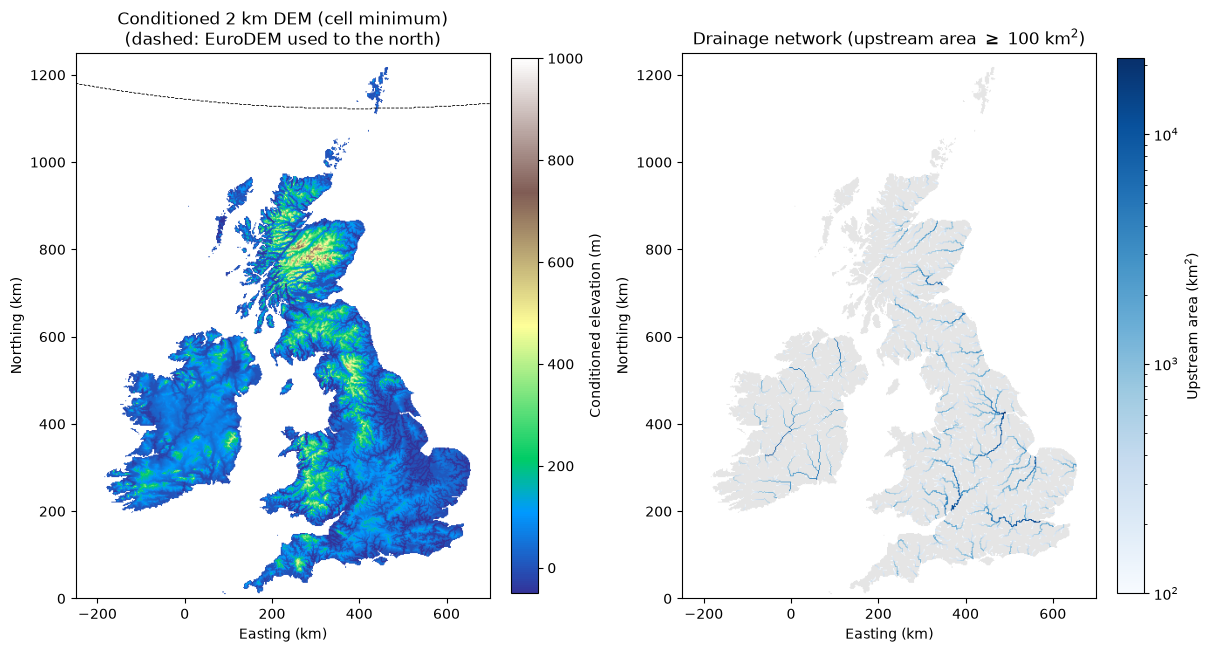

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 9), layout='constrained')
extent = (X0 / 1e3, X1 / 1e3, Y0 / 1e3, Y1 / 1e3)

ax = axes[0]
im = ax.imshow(np.where(land, dem_cond, np.nan), extent=extent, cmap='terrain', vmin=-50, vmax=1000)
ax.contour(np.where(use_eu, 1, 0), levels=[0.5], extent=extent, origin='upper', colors='k', linewidths=0.6, linestyles='--')
fig.colorbar(im, ax=ax, shrink=0.6, label='Conditioned elevation (m)')
ax.set_title('Conditioned 2 km DEM (cell minimum)\n(dashed: EuroDEM used to the north)')

ax = axes[1]
area_km2 = np.where(land, acc * RES**2 / 1e6, np.nan)
ax.imshow(np.where(land, 0.0, np.nan), extent=extent, cmap=mcolors.ListedColormap(['0.9']))
im = ax.imshow(np.where(area_km2 >= 100, area_km2, np.nan), extent=extent, cmap='Blues',
               norm=mcolors.LogNorm(vmin=100, vmax=area_km2[land].max()))
fig.colorbar(im, ax=ax, shrink=0.6, label='Upstream area (km$^2$)')
ax.set_title('Drainage network (upstream area $\\geq$ 100 km$^2$)')

for ax in axes:
    ax.set_xlabel('Easting (km)')
    ax.set_ylabel('Northing (km)')
    ax.set_aspect('equal')

## Metadata

In [12]:
lines = [
    '2 km D8 flow direction for the British Isles (GB, island of Ireland, Isle of Man) in British National Grid (EPSG:27700).',
    '',
    'Made by `notebooks/2026-11-02_1_uk-flowdir-2km.ipynb`. Elevation comes from HydroSHEDS v1 `eu_con_3s` (90 m conditioned DEM): '
    'each 2 km cell takes the minimum of its 90 m land pixels, which keeps the burned-in river channels and narrow valleys. Cells not wholly south of 60°N (northern Shetland) use EuroDEM 2023 instead. '
    'A cell is land if it is at least 50% land. '
    f'In GB, OS Open Rivers (2018, canals excluded) rivers with at least {MIN_UP_KM} km of channel upstream are enforced: their cells take D8 directions along the mapped river '
    f'and are lowered by {BURN} m. Ireland is DEM-only. '
    'The DEM is conditioned with Priority-Flood+ε (Barnes et al., 2014), adapted so enforced directions are downhill. D8 directions '
    'are taken from the conditioned DEM, plus the enforced directions on river cells. Every land cell has a strictly downhill path to the sea: there are no pits, flats, depressions or loops. '
    'Coastal cells drain directly to an adjacent sea cell.',
    '',
    f'Against {len(err)} NRFA gauges (>= 50 km2), the median absolute error in upstream area is {100 * err.abs().median():.1f}% '
    f'({100 * err_dem_only.abs().median():.1f}% without river enforcement), and {100 * (err.abs() > 0.3).mean():.1f}% of gauges are more than 30% off.',
    '',
    f'Grid: {ncol} x {nrow} cells of {RES} m, extent x {X0} to {X1}, y {Y0} to {Y1} (BNG metres). Sea and nodata = {NODATA}.',
    '',
    'Flow direction encoding (as in the HMF 5 km grid): 1 = E, 2 = SE, 4 = S, 8 = SW, 16 = W, 32 = NW, 64 = N, 128 = NE.',
    '',
    'Files:',
    '- `flowdir_02000_bng.tif`: flow direction (int16).',
    '- `flowacc_02000_bng.tif`: number of 2 km cells draining through each cell, including itself (int32).',
    f'- `dem_02000_bng_conditioned.tif`: conditioned DEM (float64, m). This is a cell-minimum DEM with river cells lowered by {BURN} m, so it is '
    'only for routing, not for e.g. mean elevation or hillslope gradients. Must stay float64 to preserve the ε gradients that the directions are based on.',
]
(path_out / 'flowdir_02000_bng.tif.md').write_text('\n'.join(lines) + '\n')
print('\n'.join(lines))

2 km D8 flow direction for the British Isles (GB, island of Ireland, Isle of Man) in British National Grid (EPSG:27700).

Made by `notebooks/2026-11-02_1_uk-flowdir-2km.ipynb`. Elevation comes from HydroSHEDS v1 `eu_con_3s` (90 m conditioned DEM): each 2 km cell takes the minimum of its 90 m land pixels, which keeps the burned-in river channels and narrow valleys. Cells not wholly south of 60°N (northern Shetland) use EuroDEM 2023 instead. A cell is land if it is at least 50% land. In GB, OS Open Rivers (2018, canals excluded) rivers with at least 10 km of channel upstream are enforced: their cells take D8 directions along the mapped river and are lowered by 50 m. Ireland is DEM-only. The DEM is conditioned with Priority-Flood+ε (Barnes et al., 2014), adapted so enforced directions are downhill. D8 directions are taken from the conditioned DEM, plus the enforced directions on river cells. Every land cell has a strictly downhill path to the sea: there are no pits, flats, depressions or 